# Who Delivers When It Matters? — Pressure Analytics for T20 Competitions (2022 →)
**SupeRR Selector Season 2 · Round 1** &nbsp;|&nbsp; Author: Swastik Swarup Meher

**Question.** Which batters and bowlers perform best in high-pressure match situations, relative to what an average player produces in the *same* situation and relative to their own usual level?

**Pipeline**

| # | Stage | Output |
|---|---|---|
| 1 | Load, scope, data-quality audit | clean ball-by-ball table |
| 2 | Match-state features (score, wickets, balls left, target, RRR…) | state before every delivery |
| 3 | Win-probability model (out-of-fold) | WP before/after each ball |
| 4 | **Pressure Index** (leverage in chases, collapse index in 1st innings) | pressure / ordinary balls |
| 5 | Context-expected runs & wickets (out-of-fold) | player-vs-expectation metrics |
| 6 | Player ratings: shrinkage, eligibility, composite | ranked batters & bowlers |
| 7 | Reliability: split-half, bootstrap, weight sensitivity | how much to trust the ranks |

Everything below is reproducible from the six CSVs. Set `DATA_DIR` in the first code cell.

## 0 · Setup

### Notebook environment

Select the Python kernel that has this project's packages. If imports fail, run `%pip install -r ../requirements.txt` when the notebook kernel's working directory is `src`, or `%pip install -r requirements.txt` when it is the project root. `%pip` installs into the active notebook kernel; a terminal `pip` may target a different Python. Restart the kernel after installation and select the same interpreter under VS Code **Select Kernel** so Pylance can resolve imports.


In [23]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier as HGC, HistGradientBoostingRegressor as HGR
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})

# Resolve paths from either the repository root or src, and send every notebook
# artifact to the same project-root output directory as player_rankings.py.
cwd = Path.cwd()
if (cwd / 'data').is_dir():
    REPO_ROOT = cwd
elif (cwd.parent / 'data').is_dir():
    REPO_ROOT = cwd.parent
else:
    raise FileNotFoundError('Cannot locate the project data/ folder from this notebook directory.')
DATA_DIR = str(REPO_ROOT / 'data') + os.sep
OUT_DIR = str(REPO_ROOT / 'pressure_outputs') + os.sep

# ---------------- configuration ----------------
PRESSURE_PCT, ORDINARY_PCT = 80, 50       # Pressure Index cut-offs (percentile within innings)
MIN_BAT_BALLS, MIN_BAT_MATCH   = 100, 15  # eligibility: pressure balls faced / matches
MIN_BOWL_BALLS, MIN_BOWL_MATCH = 90, 15  # eligibility: pressure legal balls bowled / matches
INST_MIN = 6                              # a pressure instance needs >= 6 pressure balls
N_BOOT, N_SPLIT = 300, 60                 # bootstrap / split-half repetitions
SEED = 7
os.makedirs(OUT_DIR, exist_ok=True); rng = np.random.default_rng(SEED)


## 1 · Data loading, scope and quality audit
**Scope rules**
* IPL 2022-26 and full T20Is only (the two A-team tournaments are excluded – not IPL, not T20I).
* Drop D/L / reduced-over matches, super-over matches and no-results: chase arithmetic is not comparable there.
* Innings 1 and 2 only.

In [24]:
b = pd.read_csv(DATA_DIR+'ball_by_ball.csv'); m = pd.read_csv(DATA_DIR+'matches.csv'); comps = pd.read_csv(DATA_DIR+'competitions.csv')
print('raw deliveries:', len(b), '| raw matches:', len(m))
m = m.merge(comps[['comp_id','comp_name','match_format']], on='comp_id')
m = m[(m.match_format=='T20I') | m.comp_name.str.startswith('IPL')]
m['is_ipl'] = m.comp_name.str.startswith('IPL').astype(int)
m = m[m.revised_target.isna() & m.first_inn_revised_overs.isna() & m.second_inn_revised_overs.isna()]
m = m[m.win_team_id.notna() & (m.win_team_id > 0)]
m = m[~m.match_id.isin(b[b.innings > 2].match_id.unique())]
b = b[b.match_id.isin(m.match_id) & (b.innings <= 2)].copy()
ok = b.groupby('match_id').innings.nunique(); b = b[b.match_id.isin(ok[ok==2].index)]
b = b.merge(m[['match_id','is_ipl','comp_name','match_date','win_team_id']], on='match_id')
b = b.sort_values(['match_id','innings','innings_ball_num']).reset_index(drop=True)
print('in scope -> matches:', b.match_id.nunique(), '| deliveries:', len(b), '| IPL matches:', int(b.groupby('match_id').is_ipl.first().sum()),
      '| T20I matches:', int((1-b.groupby('match_id').is_ipl.first()).sum()))

raw deliveries: 200999 | raw matches: 883
in scope -> matches: 784 | deliveries: 187142 | IPL matches: 355 | T20I matches: 429


### 1.1 Data-quality finding: `runs` is *runs off the bat only*
Wides / byes / leg-byes show `runs = 0`, and `extras1_runs` is a type code (wide=2, leg-bye=3 …), not a run count.  
So team totals, targets and required rates would be understated. I reconcile innings totals against the stated winning margin in
"won by N runs" matches and regress the residual on the extras counts to recover run values per extra type.

In [25]:
et = b.extras_type
b['wd'] = (et=='wide').astype(int); b['nb'] = (et=='Overstep').astype(int); b['lb'] = et.isin(['legbyes','byes']).astype(int)
g = b.groupby(['match_id','innings']).agg(bat=('runs','sum'), wd=('wd','sum'), nb=('nb','sum'), lb=('lb','sum')).unstack()
g.columns = [f'{a}{i}' for a, i in g.columns]
rr = m[m.result.str.contains(r'by \d+ runs?', case=False, na=False)].copy()
rr['margin'] = rr.result.str.extract(r'by (\d+) run', flags=2)[0].astype(float)
j = rr.set_index('match_id').join(g, how='inner')
j['gap'] = j.margin - (j.bat1 - j.bat2)                      # runs not captured by the `runs` column
X = pd.DataFrame({'wide': j.wd1-j.wd2, 'no-ball': j.nb1-j.nb2, 'bye/leg-bye': j.lb1-j.lb2})
keep = j.gap.abs() < 30                                       # ignore a handful of corrupt rows
coef = np.linalg.lstsq(X[keep].values, j.gap[keep].values, rcond=None)[0]
print(f'{keep.sum()} run-margin matches used. Estimated runs per extra:', dict(zip(X.columns, coef.round(2))))
print('mean |gap| if extras ignored:', j.gap[keep].abs().mean().round(2), ' -> after applying (1, 1, 1.5):',
      (j.gap - (X.iloc[:,0]*1 + X.iloc[:,1]*1 + X.iloc[:,2]*1.5))[keep].abs().mean().round(2))

385 run-margin matches used. Estimated runs per extra: {'wide': np.float64(1.12), 'no-ball': np.float64(1.02), 'bye/leg-bye': np.float64(1.42)}
mean |gap| if extras ignored: 4.87  -> after applying (1, 1, 1.5): 2.41


In [26]:
# Adopted run values for team-level arithmetic: wide=1, no-ball=+1, bye/leg-bye=1.5   (bat-runs credit stays exact)
b['legal']     = (~et.isin(['wide','Overstep','Penalty'])).astype(int)    # wides / no-balls are not legal balls
b['faced']     = (b.wd==0).astype(int)                                     # batter does not face a wide
b['tot_runs']  = b.runs + b.wd*1 + b.nb*1 + b.lb*1.5
b['bowl_runs'] = b.runs + b.wd + b.nb                                      # byes/leg-byes are not charged to the bowler
dt = b.dismissal_type.fillna('')
b['wkt']      = b.is_wicket.astype(int)
b['runout']   = (dt=='RunOut').astype(int); b['retire'] = (dt=='Retire Out').astype(int)
b['bowl_wkt'] = dt.isin(['Caught','Bowled','LBW','Stump','Hit Wicket']).astype(int)      # wickets credited to the bowler
b['bat_dis']  = ((b.wkt==1) & (b.dismissed_player_id==b.striker_id) & (b.retire==0)).astype(int)
b['bat_win']  = (b.win_team_id==b.batting_team_id).astype(int)

## 2 · Match state before every delivery
`balls_left`, `wk_b` (wickets lost), `score_b`, `crr`; for chases also `target`, runs needed (`rn`), required rate (`rrr`) and `rr_gap = rrr − crr`.
All features use information available **before** the ball is bowled.

In [27]:
g = b.groupby(['match_id','innings'])
b['score_b'] = g.tot_runs.cumsum() - b.tot_runs
b['legal_b'] = g.legal.cumsum() - b.legal
b['wk_b']    = g.wkt.cumsum() - b.wkt
b['balls_left'] = (120 - b.legal_b).clip(lower=0)
b['crr'] = b.score_b*6 / b.legal_b.clip(lower=1)
b = b.merge(b[b.innings==1].groupby('match_id').tot_runs.sum().rename('inn1_tot'), on='match_id')
b['target'] = np.where(b.innings==2, b.inn1_tot+1, np.nan)
b['rn']  = np.where(b.innings==2, (b.target-b.score_b).clip(lower=1), np.nan)
b['rrr'] = np.where(b.innings==2, b.rn*6/b.balls_left.clip(lower=1), np.nan)
b['rr_gap'] = b.rrr - b.crr
FEAT_ALL = ['innings','balls_left','wk_b','score_b','crr','rn','rrr','rr_gap','is_ipl']
FEAT_1   = ['balls_left','wk_b','score_b','crr','is_ipl']
FEAT_2   = ['balls_left','wk_b','score_b','crr','rn','rrr','rr_gap','is_ipl']
b[['match_id','innings','legal_b','score_b','wk_b','target','rn','rrr']].query('innings==2').head()

,match_id,innings,legal_b,score_b,wk_b,target,rn,rrr
121,13511,2,0,0.0,0,104.0,104.0,5.200000
122,13511,2,1,0.0,0,104.0,104.0,5.243697
123,13511,2,2,4.0,0,104.0,100.0,5.084746
124,13511,2,3,4.0,0,104.0,100.0,5.128205
125,13511,2,4,4.0,0,104.0,100.0,5.172414


## 3 · Win-probability model
Gradient-boosted classifiers, one per innings, predicting *“does the batting side win?”* from the pre-ball state.
**All predictions are out-of-fold with `GroupKFold` by match**, so no match is ever predicted by a model that saw it.
Win probability (WP) gives each ball a *win-probability swing*: `ΔWP = WP_after − WP_before`.

In [28]:
folds = GroupKFold(n_splits=5)
def oof_clf(X, y, groups):
    p = np.zeros(len(y))
    for tr, te in folds.split(X, y, groups):
        p[te] = HGC(max_depth=4, learning_rate=.05, max_iter=250, min_samples_leaf=300, l2_regularization=2., early_stopping=False, random_state=SEED).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:,1]
    return p
def oof_reg(X, y, groups):
    p = np.zeros(len(y))
    for tr, te in folds.split(X, y, groups):
        p[te] = HGR(max_depth=5, learning_rate=.05, max_iter=200, min_samples_leaf=300, l2_regularization=2., early_stopping=False, random_state=SEED).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
    return p

b['wp_pre'] = np.nan
for inn, fs in [(1, FEAT_1), (2, FEAT_2)]:
    ix = b.innings==inn
    b.loc[ix,'wp_pre'] = oof_clf(b.loc[ix,fs], b.loc[ix,'bat_win'], b.loc[ix,'match_id'])
    y, p = b.loc[ix,'bat_win'], b.loc[ix,'wp_pre']
    print(f'Innings {inn}: AUC={roc_auc_score(y,p):.3f}  log-loss={log_loss(y,p):.3f} (naive 0.693)  Brier={brier_score_loss(y,p):.3f}')

# WP after each ball = WP before the next ball; innings-end uses the result / the chase's opening WP
b['wp_post'] = b.groupby(['match_id','innings']).wp_pre.shift(-1)
first2 = b[b.innings==2].groupby('match_id').wp_pre.first()
for i in b.groupby(['match_id','innings']).tail(1).index:
    r = b.loc[i]; b.loc[i,'wp_post'] = r.bat_win if r.innings==2 else 1 - first2.get(r.match_id, .5)
b['dwp'] = b.wp_post - b.wp_pre
b.loc[b.retire==1,'dwp'] = 0
b['abs_dwp'] = b.dwp.abs()

Innings 1: AUC=0.678  log-loss=0.647 (naive 0.693)  Brier=0.226
Innings 2: AUC=0.893  log-loss=0.409 (naive 0.693)  Brier=0.133


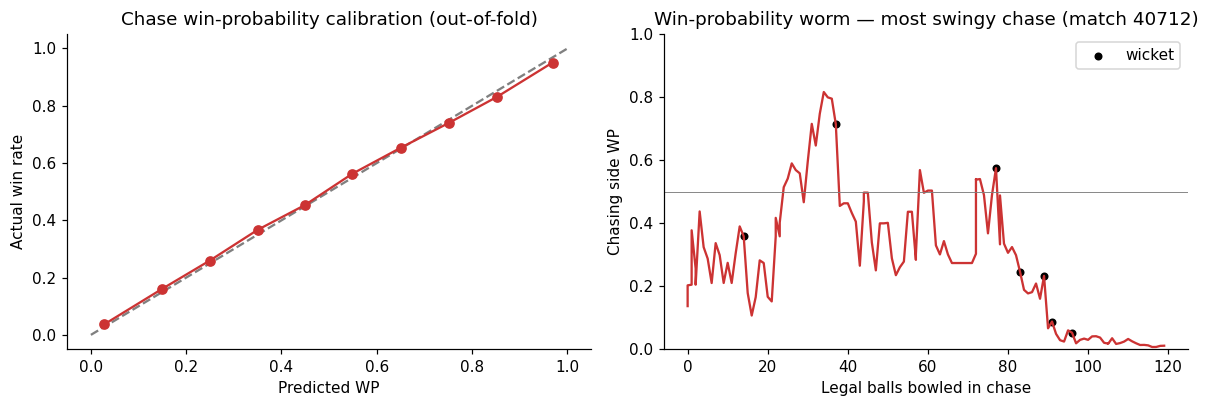

In [29]:
# calibration check of the chase model + a 'worm' of the most pivotal chase
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
c2 = b[b.innings==2]; bins = pd.cut(c2.wp_pre, np.linspace(0,1,11))
cal = c2.groupby(bins).agg(pred=('wp_pre','mean'), actual=('bat_win','mean'))
ax[0].plot([0,1],[0,1],'--',color='grey'); ax[0].plot(cal.pred, cal.actual,'o-',color='#c33')
ax[0].set(title='Chase win-probability calibration (out-of-fold)', xlabel='Predicted WP', ylabel='Actual win rate')
mid = c2.groupby('match_id').abs_dwp.sum().idxmax(); w = c2[c2.match_id==mid]
ax[1].plot(w.legal_b, w.wp_pre, color='#c33'); ax[1].axhline(.5, color='grey', lw=.6)
wk = w[w.wkt==1]; ax[1].scatter(wk.legal_b, wk.wp_pre, color='k', s=18, label='wicket'); ax[1].legend()
ax[1].set(title=f'Win-probability worm — most swingy chase (match {mid})', xlabel='Legal balls bowled in chase', ylabel='Chasing side WP', ylim=(0,1))
plt.tight_layout(); plt.savefig(OUT_DIR+'fig_wp_model.png', dpi=150); plt.show()

## 4 · Defining pressure — the Pressure Index (PI)
Pressure is computed from the **pre-ball state only**, so it is independent of what happens on the ball (no outcome leakage).

**Chase (innings 2) – leverage.** A second model predicts the expected size of the win-probability swing from the state. High expected swing ⇒ the next ball can decide the match ⇒ high pressure.
This automatically encodes required rate, balls left, wickets in hand and how close the game is — e.g. *“need 35 off 12”*.

**First innings – damage index.** With no target the WP model is nearly flat (AUC≈0.68), so leverage is noise. Pressure instead = wickets lost above the league norm for that stage (z-score) + 0.5 × shortfall vs par score (z-score).
This captures *early-wicket collapses* and rebuilding phases.

`PI` = percentile within innings. **Pressure ball: PI ≥ 80 (top 20%)**; **ordinary ball: PI < 50** (the “usual performance” baseline).

In [30]:
b['LI'] = np.nan
ix = b.innings==2
b.loc[ix,'LI'] = oof_reg(b.loc[ix,FEAT_2], b.loc[ix,'abs_dwp'], b.loc[ix,'match_id'])     # expected |WP swing| (chase leverage)

i1 = b.innings==1
b['stage'] = (b.legal_b//6).clip(upper=19)
st = b[i1].groupby('stage').agg(wk_m=('wk_b','mean'), wk_s=('wk_b','std'), sc_m=('score_b','mean'), sc_s=('score_b','std'))
b = b.join(st, on='stage')
zw = ((b.wk_b-b.wk_m)/b.wk_s.clip(lower=.35)).clip(-3,3); zs = ((b.sc_m-b.score_b)/b.sc_s.clip(lower=3)).clip(-3,3)
b['dmg'] = np.where(i1, zw + .5*zs, np.nan)
raw = b.dmg.where(i1).fillna(b.LI.where(~i1))
b['PI'] = raw.groupby(b.innings).rank(pct=True)*100
b['pressure'] = (b.PI>=PRESSURE_PCT).astype(int); b['ordinary'] = (b.PI<ORDINARY_PCT).astype(int)
print(f'pressure deliveries: {b.pressure.sum():,} ({b.pressure.mean():.1%});  ordinary: {b.ordinary.sum():,}')

pressure deliveries: 37,434 (20.0%);  ordinary: 93,584


### 4.1 Does the PI separate pressure from ordinary play?

,balls,batting_WP,SR,dismissals_per100,avg_abs_dWP
band,,,,,
<50 ordinary,89832,0.551,147.461,5.585,0.014
50-80,54189,0.473,134.258,4.949,0.023
80-90 pressure,18039,0.386,131.482,5.338,0.028
90-100 extreme,17866,0.340,126.766,6.168,0.038


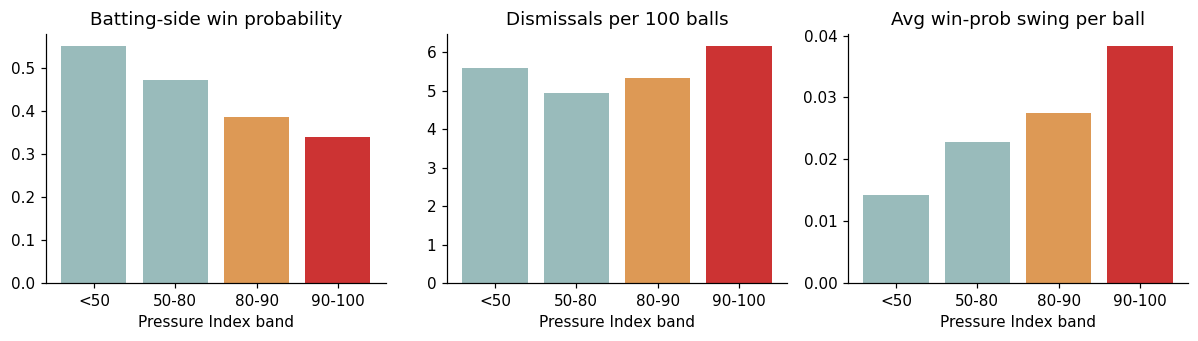

,deliveries,median PI,% flagged pressure
Chase: need ~35 off 12,153.0,91.0,63.0
"Chase: need ~12 off 12, 6 down",11.0,91.0,100.0
Chase: need ~60 off 30,141.0,90.0,65.0
"Chase: need ~20 off 36, <=2 down",11.0,7.0,0.0
1st inn: >=3 wkts in first 6 overs,1600.0,95.0,97.0
1st inn: 4+ down by over 10,2673.0,88.0,81.0
1st inn: steady powerplay (0-1 down),23969.0,40.0,6.0


In [31]:
b['band'] = pd.cut(b.PI, [0,50,80,90,100], include_lowest=True, labels=['<50 ordinary','50-80','80-90 pressure','90-100 extreme'])
f = b[b.faced==1].groupby('band').agg(balls=('PI','size'), batting_WP=('wp_pre','mean'), SR=('runs', lambda s: 100*s.mean()),
                                      dismissals_per100=('bat_dis', lambda s: 100*s.mean()), avg_abs_dWP=('abs_dwp','mean'))
display(f.round(3))
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2)); cols = ['#9bb','#9bb','#d95','#c33']
for a, (c, t) in zip(ax, [('batting_WP','Batting-side win probability'), ('dismissals_per100','Dismissals per 100 balls'), ('avg_abs_dWP','Avg win-prob swing per ball')]):
    a.bar(range(4), f[c], color=cols); a.set_xticks(range(4)); a.set_xticklabels(['<50','50-80','80-90','90-100']); a.set_title(t); a.set_xlabel('Pressure Index band')
plt.tight_layout(); plt.savefig(OUT_DIR+'fig_pressure_validation.png', dpi=150); plt.show()

# the situations named in the brief
ch = b[b.innings==2]; i1d = b[b.innings==1]
ex = {'Chase: need ~35 off 12':              (ch, ch.rn.between(33,37)&ch.balls_left.between(11,13)),
      'Chase: need ~12 off 12, 6 down':      (ch, ch.rn.between(11,13)&ch.balls_left.between(11,13)&(ch.wk_b==6)),
      'Chase: need ~60 off 30':              (ch, ch.rn.between(58,62)&ch.balls_left.between(29,31)),
      'Chase: need ~20 off 36, <=2 down':    (ch, ch.rn.between(18,22)&ch.balls_left.between(35,37)&(ch.wk_b<=2)),
      '1st inn: >=3 wkts in first 6 overs':  (i1d, (i1d.wk_b>=3)&(i1d.legal_b<36)),
      '1st inn: 4+ down by over 10':         (i1d, (i1d.wk_b>=4)&i1d.legal_b.between(54,66)),
      '1st inn: steady powerplay (0-1 down)':(i1d, (i1d.wk_b<=1)&(i1d.legal_b<36))}
display(pd.DataFrame({k: {'deliveries': int(mk.sum()), 'median PI': d[mk].PI.median(), '% flagged pressure': 100*d[mk].pressure.mean()} for k,(d,mk) in ex.items()}).T.round(0))

### 4.2 What do pressure balls look like?

In [32]:
fa = b[b.faced==1]
prof = fa.assign(kind=np.where(fa.pressure==1,'pressure',np.where(fa.ordinary==1,'ordinary','middle'))).groupby(['innings','kind']).agg(
    balls=('runs','size'), SR=('runs', lambda s: 100*s.mean()), dismissals_per100=('bat_dis', lambda s: 100*s.mean()),
    dot_pct=('runs', lambda s: 100*(s==0).mean()), batting_WP=('wp_pre','mean'))
display(prof.round(2))
allp = fa.assign(kind=np.where(fa.pressure==1,'pressure','ordinary')).query('pressure==1 or ordinary==1').groupby('kind').agg(
    SR=('runs', lambda s: 100*s.mean()), dismissals_per100=('bat_dis', lambda s: 100*s.mean()), batting_WP=('wp_pre','mean')); display(allp.round(2))
pr = b[b.pressure==1]
tags = {'Chase, <=24 balls left': (pr.innings==2)&(pr.balls_left<=24), 'Chase, 25-48 balls left': (pr.innings==2)&pr.balls_left.between(25,48),
        'Chase, >48 balls left': (pr.innings==2)&(pr.balls_left>48), '1st inn: collapse (>=3 wkts by over 10)': (pr.innings==1)&(pr.wk_b>=3)&(pr.legal_b<60),
        '1st inn: other damage / under par': (pr.innings==1)&~((pr.wk_b>=3)&(pr.legal_b<60))}
display(pd.DataFrame({k: {'pressure deliveries': int(v.sum()), 'share': round(v.mean(),3)} for k, v in tags.items()}).T)

balls      SR  dismissals_per100  dot_pct  batting_WP
innings kind                                                           
1       middle    28210  134.82               5.13    36.93        0.45
        ordinary  46658  157.44               5.53    32.68        0.62
        pressure  18870  110.79               5.07    44.31        0.27
2       middle    25979  133.65               4.75    38.84        0.49
        ordinary  43174  136.68               5.64    37.59        0.47
        pressure  17035  149.45               6.50    36.57        0.47

,SR,dismissals_per100,batting_WP
kind,,,
ordinary,147.46,5.58,0.55
pressure,129.14,5.75,0.36


,pressure deliveries,share
"Chase, <=24 balls left",5351.0,0.143
"Chase, 25-48 balls left",4653.0,0.124
"Chase, >48 balls left",7916.0,0.211
1st inn: collapse (>=3 wkts by over 10),5565.0,0.149
1st inn: other damage / under par,13949.0,0.373


## 5 · Context-expected outcomes and per-ball credit
Four more out-of-fold models give the **league-average outcome for the same match state**:
expected bat runs, expected dismissal probability, expected runs conceded and expected bowler-wicket probability.  
A player is judged against *these*, so a death-overs finisher and an opener in a collapse are each compared with a fair peer group.

Attribution: run-outs/retirements are neutral for bowlers; a run-out of the non-striker is neutral for the striker.

In [ ]:
X = b[FEAT_ALL]; gr = b.match_id; fa = b.faced==1
b['e_bat_runs'] = np.nan; b['e_bat_dis'] = np.nan
b.loc[fa,'e_bat_runs'] = oof_reg(X[fa], b.loc[fa,'runs'],    gr[fa])
b.loc[fa,'e_bat_dis']  = np.clip(oof_reg(X[fa], b.loc[fa,'bat_dis'], gr[fa]), 0, 1)
b['e_bowl_runs'] = oof_reg(X, b.bowl_runs, gr)
b['e_bowl_wkt']  = np.clip(oof_reg(X, b.bowl_wkt, gr), 0, 1)
b['wpa_bat']  = b.dwp.where(~((b.runout==1)&(b.bat_dis==0)), 0.)
b['wpa_bowl'] = (-b.dwp).where((b.runout==0)&(b.retire==0), 0.)

bat = b[b.faced==1].copy()
bat['pid'], bat['pname'] = bat.striker_id, bat.striker_name
bat['rae'] = bat.runs - bat.e_bat_runs            # runs above expected
bat['dav'] = bat.e_bat_dis - bat.bat_dis          # dismissals avoided vs expected
bat['wpa'] = bat.wpa_bat
bowl = b.copy(); bowl['pid'], bowl['pname'] = bowl.bowler_id, bowl.bowler_name
bowl['rae'] = bowl.e_bowl_runs - bowl.bowl_runs   # runs SAVED vs expected
bowl['dav'] = bowl.bowl_wkt - bowl.e_bowl_wkt     # wickets above expected
bowl['wpa'] = bowl.wpa_bowl
print('batter rows:', len(bat), '| bowler rows:', len(bowl))

## 6 · Player ratings
**Metrics (pressure balls only)**

| Metric | Batter | Bowler |
|---|---|---|
| **RAE** (main) | runs above expected / 100 balls | runs saved vs expected / 100 deliveries |
| **Wicket** | dismissals avoided vs expected | wickets above expected |
| **WPA** | win probability added | win probability added for the fielding side |
| **Delta** | pressure RAE − own RAE on ordinary balls | same |
| **Consistency** | share of pressure innings/spells (≥6 balls) with WPA > 0 | same |

**Sample size:** empirical-Bayes shrinkage, `k = within-player variance / between-player variance`, estimated from the data.  
**Weights** come from the reliability diagnostics in §7 (runs-vs-context is the only strongly repeatable component, so it dominates).

In [ ]:
WB = dict(wpa100=.15, rae100=.60, dav100=.10, delta=.15, consis=0.0)   # batters
WL = dict(wpa100=.15, rae100=.55, dav100=.10, delta=.10, consis=.10)   # bowlers

def per_match(df):
    """(player, match) sums: everything downstream is linear in match weights -> cheap bootstrap / split-half."""
    p, o = df[df.pressure==1], df[df.ordinary==1]
    A = p.groupby(['pid','match_id']).agg(n_p=('rae','size'), wpa_p=('wpa','sum'), rae_p=('rae','sum'), dav_p=('dav','sum'))
    B = o.groupby(['pid','match_id']).agg(n_o=('rae','size'), rae_o=('rae','sum'))
    pm = A.join(B, how='outer').fillna(0).reset_index()
    pm['inst'] = (pm.n_p>=INST_MIN).astype(int); pm['succ'] = ((pm.n_p>=INST_MIN)&(pm.wpa_p>0)).astype(int)
    return pm

def eb_k(df, col, mask_col, minn=30):
    d = df[df[mask_col]==1]; s2 = d[col].var()
    g = d.groupby('pid')[col].agg(['mean','size']); g = g[g['size']>=minn]
    tau2 = g['mean'].var() - (s2/g['size']).mean()
    return float(np.clip(s2/tau2, 20, 3000)) if tau2>0 else 3000.

def components(a, ks, base, kc=6):
    sh = lambda t, n, k: t/(n+k)
    o = pd.DataFrame(index=a.index)
    o['wpa100'] = 100*sh(a.wpa_p, a.n_p, ks['wpa']);  o['rae100'] = 100*sh(a.rae_p, a.n_p, ks['rae']);  o['dav100'] = 100*sh(a.dav_p, a.n_p, ks['dav'])
    o['rae_ord'] = 100*sh(a.rae_o, a.n_o, ks['rae_o']);  o['delta'] = o.rae100 - o.rae_ord
    o['consis'] = (a.succ + kc*base)/(a.inst + kc)
    return o

def composite(o, elig, w):
    z = (o.loc[elig, list(w)] - o.loc[elig, list(w)].mean()) / o.loc[elig, list(w)].std()
    return sum(w[k]*z[k] for k in w)

SPEC = {'bat':  dict(df=bat,  w=WB, minb=MIN_BAT_BALLS,  minm=MIN_BAT_MATCH),
        'bowl': dict(df=bowl, w=WL, minb=MIN_BOWL_BALLS, minm=MIN_BOWL_MATCH)}
R = {}
for kind, s in SPEC.items():
    d = s['df']; pm = per_match(d)
    legal_n = (d[(d.pressure==1)&(d.legal==1)] if kind=='bowl' else d[d.pressure==1]).groupby('pid').size()
    mt = pm[pm.n_p>0].groupby('pid').size()
    elig = legal_n[legal_n>=s['minb']].index.intersection(mt[mt>=s['minm']].index)
    ks = dict(wpa=eb_k(d,'wpa','pressure'), rae=eb_k(d,'rae','pressure'), dav=eb_k(d,'dav','pressure'), rae_o=eb_k(d,'rae','ordinary'))
    base = pm.succ.sum()/pm.inst.sum()
    o = components(pm.groupby('pid').sum(numeric_only=True), ks, base)
    o['score'] = np.nan; o.loc[elig,'score'] = composite(o, elig, s['w'])
    R[kind] = dict(pm=pm, ks=ks, base=base, elig=elig, sc=o, w=s['w'], d=d)
    print(f'{kind}: eligible = {len(elig)} | shrinkage k = { {k: round(v) for k,v in ks.items()} }')

bat: eligible = 102 | shrinkage k = {'wpa': 3000, 'rae': 262, 'dav': 1154, 'rae_o': 225}
bowl: eligible = 97 | shrinkage k = {'wpa': 3000, 'rae': 193, 'dav': 3000, 'rae_o': 240}


In [ ]:
names = pd.concat([b.groupby('striker_id').striker_name.agg(lambda s: s.mode()[0]), b.groupby('bowler_id').bowler_name.agg(lambda s: s.mode()[0])])
names = names[~names.index.duplicated()]

def leaderboard(kind):
    r = R[kind]; d, o, el = r['d'], r['sc'], r['elig']; p, od = d[d.pressure==1], d[d.ordinary==1]
    if kind=='bat':
        ag = p.groupby('pid').agg(press_balls=('runs','size'), matches=('match_id','nunique'), runs=('runs','sum'), dismissals=('bat_dis','sum'),
                                  e_runs=('e_bat_runs','sum'), ipl_share=('is_ipl','mean'))
        ag['SR'] = 100*ag.runs/ag.press_balls; ag['expected_SR'] = 100*ag.e_runs/ag.press_balls; ag['avg'] = ag.runs/ag.dismissals.replace(0,np.nan)
        ag['dot%'] = 100*p.groupby('pid').runs.apply(lambda s:(s==0).mean())
        og = od.groupby('pid').agg(n=('runs','size'), r=('runs','sum')); ag['ordinary_SR'] = 100*og.r/og.n
    else:
        pl = p[p.legal==1]
        ag = p.groupby('pid').agg(matches=('match_id','nunique'), runs=('bowl_runs','sum'), e_runs=('e_bowl_runs','sum'), wkts=('bowl_wkt','sum'),
                                  e_wkts=('e_bowl_wkt','sum'), ipl_share=('is_ipl','mean'))
        ag['press_balls'] = pl.groupby('pid').size(); ag['economy'] = 6*ag.runs/ag.press_balls; ag['expected_econ'] = 6*ag.e_runs/ag.press_balls
        ag['dot%'] = 100*pl.groupby('pid').runs.apply(lambda s:(s==0).mean())
        og = od[od.legal==1].groupby('pid').agg(n=('bowl_runs','size'), r=('bowl_runs','sum')); ag['ordinary_econ'] = 6*og.r/og.n
    t = o.join(ag).loc[el].copy(); t.insert(0, 'player', names.reindex(t.index).values)
    t['rank'] = t.score.rank(ascending=False).astype(int); return t.sort_values('rank')
TB, TL = leaderboard('bat'), leaderboard('bowl')
TB.to_csv(OUT_DIR+'batters_ranked_eligible.csv'); TL.to_csv(OUT_DIR+'bowlers_ranked_eligible.csv')

## 7 · Results

### 7.1 Top-10 batters under pressure

In [ ]:
display(TB.head(10)[['rank','player','score','press_balls','matches','SR','expected_SR','avg','dot%','ordinary_SR','rae100','wpa100','dav100','delta','ipl_share']].round(2).reset_index(drop=True))

,rank,player,score,press_balls,matches,SR,expected_SR,avg,dot%,ordinary_SR,rae100,wpa100,dav100,delta,ipl_share
0,1,Glenn Maxwell,2.58,196.0,21.0,184.69,137.62,45.25,34.69,155.33,20.15,0.08,0.23,15.39,0.53
1,2,Abhishek Sharma,2.09,296.0,59.0,176.01,137.70,74.43,38.51,197.00,20.33,0.07,0.44,-14.96,0.53
2,3,Heinrich Klaasen,1.75,216.0,26.0,168.06,133.02,51.86,27.31,173.38,15.83,0.04,0.20,6.06,0.92
3,4,Tim David,1.52,364.0,42.0,166.21,143.83,35.59,34.62,184.33,13.01,0.05,0.47,0.09,0.59
4,5,Shreyas Iyer,1.40,316.0,30.0,154.43,134.38,44.36,32.91,158.57,10.96,0.05,0.32,7.23,0.78
5,6,Rinku Singh,1.37,272.0,27.0,147.06,133.59,57.14,34.93,164.39,6.86,0.10,0.67,5.74,0.70
6,7,Shai Hope,1.33,117.0,20.0,164.10,128.45,48.00,31.62,141.43,11.01,0.03,0.18,15.21,0.05
7,8,Mohammad Nabi,1.26,262.0,21.0,139.31,120.27,45.62,33.97,127.23,9.52,0.03,0.43,12.48,0.07
8,9,Rovman Powell,1.23,308.0,36.0,146.75,127.60,34.77,39.61,149.39,10.35,0.03,0.30,10.34,0.32
9,10,Aiden Markram,1.20,261.0,33.0,146.74,126.50,47.88,37.16,148.70,10.10,0.01,0.38,12.64,0.35


### 7.2 Top-10 bowlers under pressure

In [ ]:
display(TL.head(10)[['rank','player','score','press_balls','matches','economy','expected_econ','wkts','e_wkts','dot%','ordinary_econ','rae100','wpa100','dav100','delta','ipl_share']].round(2).reset_index(drop=True))

,rank,player,score,press_balls,matches,economy,expected_econ,wkts,e_wkts,dot%,ordinary_econ,rae100,wpa100,dav100,delta,ipl_share
0,1,Rashid Khan,2.00,463.0,51.0,5.92,7.57,34.0,22.87,41.90,7.67,19.06,0.08,0.32,6.57,0.54
1,2,Sunil Narine,1.86,297.0,27.0,5.54,7.71,15.0,13.40,45.12,7.43,21.89,0.05,0.05,3.00,1.00
2,3,Lockie Ferguson,1.79,171.0,23.0,6.35,8.78,12.0,10.38,51.46,9.19,18.37,0.03,0.05,19.93,0.52
3,4,Josh Hazlewood,1.62,316.0,42.0,7.12,8.27,29.0,16.48,52.22,8.96,11.67,0.08,0.38,11.42,0.59
4,5,Wanindu Hasaranga,1.48,338.0,34.0,6.53,7.42,34.0,16.87,42.60,7.83,9.34,0.07,0.51,3.24,0.35
5,6,Kuldeep Yadav,1.37,388.0,35.0,6.87,7.67,31.0,19.13,39.18,8.83,8.83,0.05,0.35,9.68,0.66
6,7,Mustafizur Rahman,1.31,441.0,41.0,6.49,8.05,30.0,28.70,48.75,8.05,17.68,0.00,0.04,2.93,0.27
7,8,Mohammed Shami,1.16,269.0,41.0,6.65,7.73,20.0,11.96,55.39,9.77,10.22,0.01,0.25,20.66,0.95
8,9,Krunal Pandya,1.12,115.0,22.0,6.10,8.12,8.0,5.96,39.13,8.20,12.38,0.03,0.07,2.42,1.00
9,10,Axar Patel,0.98,494.0,53.0,6.96,7.83,21.0,24.97,41.30,8.57,10.37,0.04,-0.11,9.38,0.50


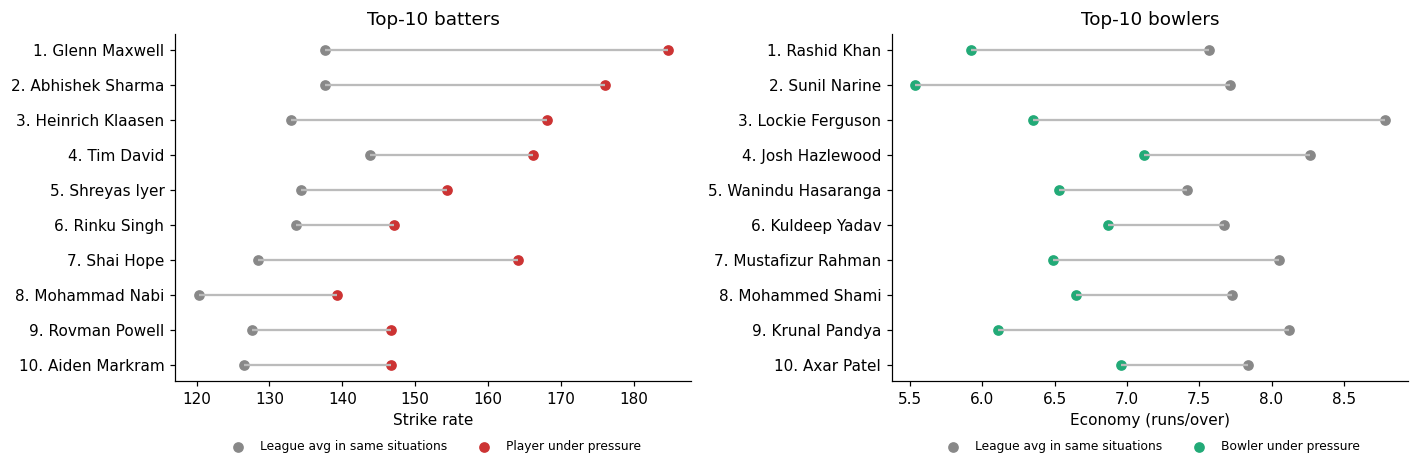

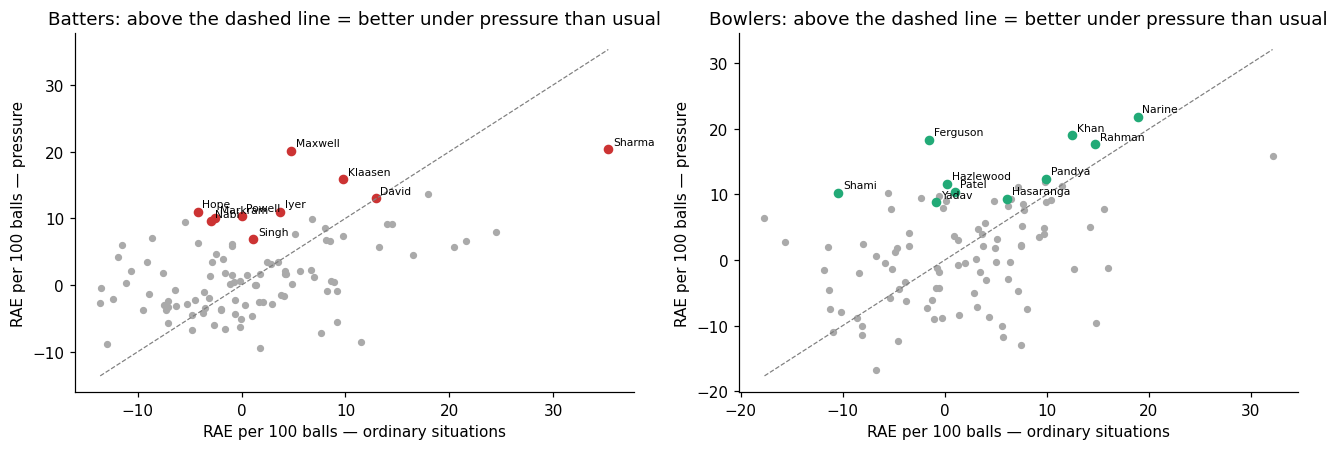

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4)); y = np.arange(10)[::-1]
t = TB.head(10); ax[0].hlines(y, t.expected_SR, t.SR, color='#bbb'); ax[0].scatter(t.expected_SR, y, color='#888', label='League avg in same situations'); ax[0].scatter(t.SR, y, color='#c33', label='Player under pressure')
ax[0].set_yticks(y); ax[0].set_yticklabels([f'{i+1}. {n}' for i, n in enumerate(t.player)]); ax[0].set(xlabel='Strike rate', title='Top-10 batters'); ax[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5,-0.14), ncol=2, frameon=False)
t = TL.head(10); ax[1].hlines(y, t.economy, t.expected_econ, color='#bbb'); ax[1].scatter(t.expected_econ, y, color='#888', label='League avg in same situations'); ax[1].scatter(t.economy, y, color='#2a7', label='Bowler under pressure')
ax[1].set_yticks(y); ax[1].set_yticklabels([f'{i+1}. {n}' for i, n in enumerate(t.player)]); ax[1].set(xlabel='Economy (runs/over)', title='Top-10 bowlers'); ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5,-0.14), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig(OUT_DIR+'fig_top10.png', dpi=150, bbox_inches='tight'); plt.show()

# who rises to the occasion? pressure vs ordinary level, every eligible player
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, kind, T, title in [(ax[0],'bat',TB,'Batters'), (ax[1],'bowl',TL,'Bowlers')]:
    a.scatter(T.rae_ord, T.rae100, s=14, color='#aaa'); top = T.head(10)
    a.scatter(top.rae_ord, top.rae100, s=28, color='#c33' if kind=='bat' else '#2a7')
    for _, r in top.iterrows(): a.annotate(r.player.split()[-1], (r.rae_ord, r.rae100), fontsize=7, xytext=(3,3), textcoords='offset points')
    lim = [min(T.rae_ord.min(), T.rae100.min()), max(T.rae_ord.max(), T.rae100.max())]; a.plot(lim, lim, '--', color='grey', lw=.8)
    a.set(xlabel='RAE per 100 balls — ordinary situations', ylabel='RAE per 100 balls — pressure', title=f'{title}: above the dashed line = better under pressure than usual')
plt.tight_layout(); plt.savefig(OUT_DIR+'fig_pressure_vs_ordinary.png', dpi=150); plt.show()

## 8 · Reliability — how much should we trust the ranks?
Three checks:
1. **Component split-half** – random halves of matches, correlate player scores across halves (Spearman-Brown adjusted). Shows which metrics are *signal* vs *noise*.
2. **Bootstrap** – resample matches, recompute scores, record each player's rank distribution → P(top-10).
3. **Weight sensitivity** – overlap of the top-10 under alternative weightings.

,Batters,Bowlers
RAE (runs vs context),0.23,0.48
Win prob. added,-0.00,0.22
Wickets vs expected,0.09,0.19
RAE in ordinary play,0.46,0.54
Pressure minus ordinary,0.16,0.18
Consistency rate,-0.18,0.29


,Batters,Bowlers
"corr(pressure RAE in half A, ordinary RAE in half B) - raw",0.21,0.23


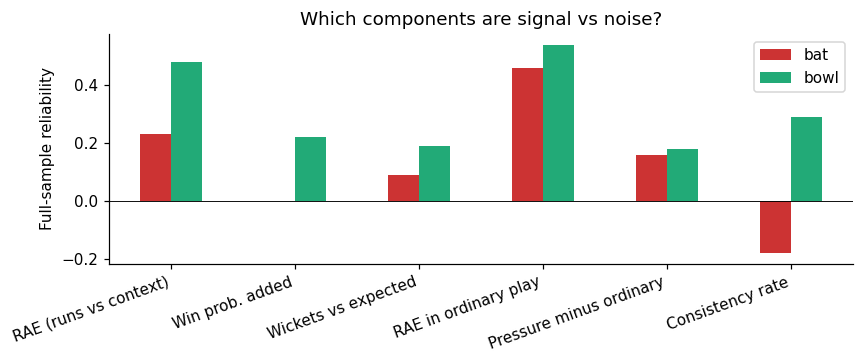

In [ ]:
def weighted_components(kind, wts):
    r = R[kind]; pm = r['pm']; cols = ['n_p','wpa_p','rae_p','dav_p','n_o','rae_o','inst','succ']
    a = pm[cols].mul(wts[pm.mi.values], axis=0).groupby(pm.pid).sum()
    return components(a, r['ks'], r['base'])
for kind in R:
    ms = R[kind]['pm'].match_id.unique(); R[kind]['pm']['mi'] = R[kind]['pm'].match_id.map(pd.Series(np.arange(len(ms)), index=ms)); R[kind]['nm'] = len(ms)

COMP = ['rae100','wpa100','dav100','rae_ord','delta','consis']
rel = {}
for kind in R:
    r = R[kind]; res = {c: [] for c in COMP}; cross = []
    for _ in range(N_SPLIT+20):
        h = (rng.random(r['nm'])<.5).astype(float); A, B_ = weighted_components(kind, h), weighted_components(kind, 1-h)
        e = A.index.intersection(B_.index).intersection(r['elig'])
        for c in COMP: res[c].append(spearmanr(A.loc[e,c], B_.loc[e,c])[0])
        cross.append(spearmanr(A.loc[e,'rae100'], B_.loc[e,'rae_ord'])[0])
    rel[kind] = pd.Series({c: np.mean(v) for c, v in res.items()}); rel[kind]['pressure(A) vs ordinary(B)'] = np.mean(cross)
rel = pd.DataFrame(rel); cross = rel.loc[['pressure(A) vs ordinary(B)']].round(2); rel = rel.drop(index='pressure(A) vs ordinary(B)')
rel_full = (2*rel/(1+rel)).round(2)       # Spearman-Brown: half-sample -> full-sample reliability (applies to split-half reliabilities only)
rel_full.index = ['RAE (runs vs context)','Win prob. added','Wickets vs expected','RAE in ordinary play','Pressure minus ordinary','Consistency rate']
cross.index = ['corr(pressure RAE in half A, ordinary RAE in half B) - raw']
display(rel_full.rename(columns={'bat':'Batters','bowl':'Bowlers'})); display(cross.rename(columns={'bat':'Batters','bowl':'Bowlers'}))
ax = rel_full.plot.bar(figsize=(8,3.4), color=['#c33','#2a7']); ax.axhline(0, color='k', lw=.6); ax.set_ylabel('Full-sample reliability'); ax.set_title('Which components are signal vs noise?')
plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.savefig(OUT_DIR+'fig_component_reliability.png', dpi=150); plt.show()


bat: bootstrap over matches (300 resamples)


,player,rank,median_rank,rank_p10,rank_p90,P(top10),P(top5)
0,Glenn Maxwell,1,2.0,1.0,12.0,0.86,0.70
1,Abhishek Sharma,2,4.0,1.0,18.1,0.77,0.59
2,Heinrich Klaasen,3,6.5,2.0,22.0,0.67,0.43
3,Tim David,4,9.0,1.0,34.0,0.55,0.38
4,Shreyas Iyer,5,11.0,2.0,39.0,0.48,0.30
5,Rinku Singh,6,12.0,4.0,29.0,0.45,0.19
6,Shai Hope,7,11.5,2.0,44.1,0.45,0.28
7,Mohammad Nabi,8,14.0,3.0,42.0,0.41,0.22
8,Rovman Powell,9,14.0,5.0,31.1,0.38,0.14
9,Aiden Markram,10,15.0,5.0,30.1,0.34,0.12



bowl: bootstrap over matches (300 resamples)


,player,rank,median_rank,rank_p10,rank_p90,P(top10),P(top5)
0,Rashid Khan,1,3.0,1.0,10.1,0.90,0.69
1,Sunil Narine,2,4.0,1.0,18.1,0.80,0.62
2,Lockie Ferguson,3,4.0,1.0,14.0,0.83,0.59
3,Josh Hazlewood,4,6.0,1.0,36.1,0.65,0.47
4,Wanindu Hasaranga,5,7.0,2.0,22.1,0.65,0.37
5,Kuldeep Yadav,6,9.0,3.0,26.1,0.57,0.31
6,Mustafizur Rahman,7,11.0,2.0,30.1,0.49,0.28
7,Mohammed Shami,8,13.0,4.0,40.1,0.40,0.17
8,Krunal Pandya,9,13.0,4.9,29.0,0.37,0.13
9,Axar Patel,10,17.0,5.0,41.0,0.30,0.14


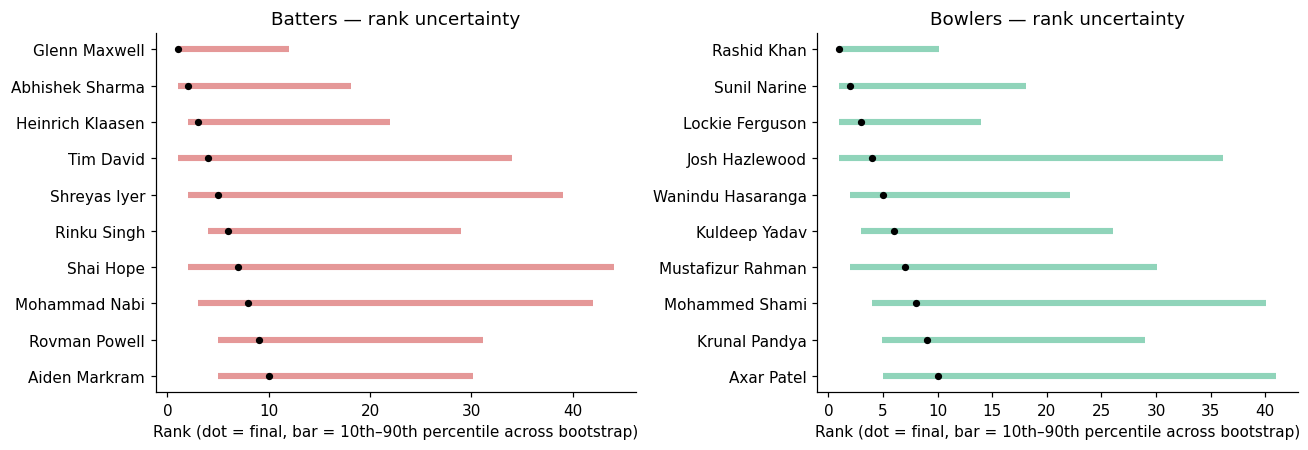

In [ ]:
boot = {}
for kind in R:
    r = R[kind]; elig = r['elig']; w = r['w']
    full = composite(weighted_components(kind, np.ones(r['nm'])), elig, w)
    ranks = np.zeros((len(full), N_BOOT)); 
    for i in range(N_BOOT):
        wts = np.bincount(rng.integers(0, r['nm'], r['nm']), minlength=r['nm']).astype(float)
        ranks[:, i] = composite(weighted_components(kind, wts), elig, w).reindex(full.index).rank(ascending=False).values
    S = pd.DataFrame({'player': names.reindex(full.index).values, 'rank': full.rank(ascending=False).astype(int).values,
                      'median_rank': np.median(ranks,1), 'rank_p10': np.quantile(ranks,.1,1), 'rank_p90': np.quantile(ranks,.9,1),
                      'P(top10)': (ranks<=10).mean(1), 'P(top5)': (ranks<=5).mean(1)}, index=full.index).sort_values('rank')
    boot[kind] = S; S.to_csv(OUT_DIR+f'{kind}_bootstrap_stability.csv')
    print(f'\n{kind}: bootstrap over matches ({N_BOOT} resamples)'); display(S.head(12).round(2).reset_index(drop=True))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, kind, col in [(ax[0],'bat','#c33'), (ax[1],'bowl','#2a7')]:
    S = boot[kind].head(10)[::-1]; yy = np.arange(len(S))
    a.hlines(yy, S.rank_p10, S.rank_p90, color=col, alpha=.5, lw=4); a.scatter(S['rank'], yy, color='k', zorder=3, s=14)
    a.set_yticks(yy); a.set_yticklabels(S.player); a.set(xlabel='Rank (dot = final, bar = 10th–90th percentile across bootstrap)', title=('Batters' if kind=='bat' else 'Bowlers')+' — rank uncertainty')
plt.tight_layout(); plt.savefig(OUT_DIR+'fig_rank_uncertainty.png', dpi=150); plt.show()

In [ ]:
ALT = lambda w: {'equal weights': {k: .2 for k in w}, 'WPA only': dict(wpa100=1, rae100=0, dav100=0, delta=0, consis=0),
                 'RAE + wickets only': dict(wpa100=0, rae100=.6, dav100=.4, delta=0, consis=0), 'no pressure-vs-ordinary delta': {**w, 'delta': 0, 'rae100': w['rae100']+w['delta']}}
rows = {}
for kind in R:
    r = R[kind]; o = weighted_components(kind, np.ones(r['nm'])); base_top = set(composite(o, r['elig'], r['w']).nlargest(10).index)
    rows[kind] = {k: len(base_top & set(composite(o, r['elig'], w).nlargest(10).index)) for k, w in ALT(r['w']).items()}
    sp = []
    for _ in range(N_SPLIT):
        h = (rng.random(r['nm'])<.5).astype(float); s1 = composite(weighted_components(kind,h), r['elig'], r['w']); s2 = composite(weighted_components(kind,1-h), r['elig'], r['w'])
        sp.append(spearmanr(s1, s2.reindex(s1.index))[0])
    rows[kind]['composite split-half rho (half-sample)'] = round(np.mean(sp), 2)
print('Overlap of the final top-10 (out of 10) under alternative weightings, and composite split-half correlation:')
display(pd.DataFrame(rows).rename(columns={'bat':'Batters','bowl':'Bowlers'}))

Overlap of the final top-10 (out of 10) under alternative weightings, and composite split-half correlation:


,Batters,Bowlers
equal weights,8.00,8.00
WPA only,6.00,6.00
RAE + wickets only,9.00,9.00
no pressure-vs-ordinary delta,9.00,8.00
composite split-half rho (half-sample),0.02,0.26


## 9 · Final submission lists

In [ ]:
# The complete, filled 10-rank submission table is generated in Section 13,
# after the full candidate pool has been scored (including low-sample players).
print('See Section 13 for the complete Top 10 batter and bowler lists.')


See Section 13 for the complete Top 10 batter and bowler lists.


## 10 · Interpretation and limitations
* **Bowling ranks are moderately reliable** (runs-saved-vs-context repeats across match halves; Rashid Khan, Hasaranga and Narine are the most secure). **Batting ranks are much noisier**: with 150-400 pressure balls per player, positions beyond the first few are statistically close — read them as a group of ~15 similar players.
* **“Clutch” as a distinct trait is barely detectable.** Pressure performance is only weakly predicted by ordinary performance in held-out matches, and win-probability-added is a noisy individual measure — that is why runs-vs-context carries most of the weight and WPA is kept as a minority, outcome-relevance term.
* **Not adjusted for:** venue/pitch, opposition strength, batting position, bowler type; target estimates carry a few runs of error because extras are not in `runs`; first-innings win probability is weak, so first-innings pressure uses a damage index.
* Changing `PRESSURE_PCT` to 70 or 85 did not change which components are repeatable.
* **Model-fit variance is itself informative.** Before the seeds were fixed, refits with different random validation splits swapped 2-3 names at the bottom of each top-10 while the leading names (Rashid Khan, Hasaranga, Narine, Hazlewood; Abhishek, Klaasen, Maxwell, Rinku, Nabi, Tim David) stayed put - consistent with the bootstrap view that positions 6-10 are statistically close. All models now use `early_stopping=False` and a fixed seed, so every run reproduces the same table.

**Reproduce:** edit `DATA_DIR`, *Run All*. Outputs (tables + figures) land in `OUT_DIR`.

## 11 · Auction Shortlist — Top-10 Batters & Top-10 Bowlers Under Pressure
Filters the 20-player shortlist through the **same shrinkage-based composite score** used in
Sections 6–8 (`TB` for batters, `TL` for bowlers).  
Players not meeting the eligibility thresholds (`MIN_BAT_BALLS`, `MIN_BOWL_BALLS`, `MIN_BAT_MATCH`, `MIN_BOWL_MATCH`)
are shown separately as **ineligible** — they have too few pressure appearances for a reliable rank.

## 12 · Pressure bowling ranking with extras control

This shortlist ranking adds the requested discipline metric to pressure bowling: **estimated wides and no-balls per six legal pressure balls**. It uses the notebook's Pressure Index (`PI ≥ PRESSURE_PCT`), which measures high-leverage states from pre-ball context. Byes and leg-byes are excluded from bowler extras.

### Algorithm

1. Aggregate all pressure deliveries and legal balls by candidate bowler.
2. Calculate pressure wickets, wicket rate per six legal balls, economy rate, and wides/no-balls per six legal balls. Also calculate overall wickets, economy, and workload.
3. For rate metrics, require at least 30 legal pressure balls; overall economy requires at least 60 legal balls. Short samples receive the worst percentile for that rate.
4. Score candidates using weighted percentiles. Pressure performance contributes 65%: pressure wickets 20%, pressure economy 20%, pressure wicket rate 10%, pressure extras rate 10%, pressure workload 5%. Overall performance contributes 35%: wickets 15%, economy 10%, and legal balls 10%.
5. Rank the 20-player shortlist and export a supplementary detailed CSV. The final full-data Top 10 is generated separately in Section 13.

This is an interpretable candidate-pool ranking. It complements the context-adjusted, shrinkage-based ratings above; it is not a claim that every raw rate is a causal measure of skill.


In [ ]:
# Pressure-first bowler score with an explicit wides/no-balls control term.
import numpy as np
import pandas as pd

# Uses every bowler in the earlier exploratory-analysis data frame.
# Section 13 is the authoritative full-data context-adjusted ranking.

bowler_names = sorted(b['bowler_name'].dropna().unique())
all_bowl = b[b.bowler_name.notna()].copy()
pressure_bowl = all_bowl[all_bowl.pressure.eq(1)].copy()

# `wd` and `nb` were reconstructed in section 1.1; count one estimated run for
# each recorded wide/Overstep. Byes and leg-byes are not bowler extras.
all_bowl['bowler_extra_est'] = all_bowl.wd + all_bowl.nb
pressure_bowl['bowler_extra_est'] = pressure_bowl.wd + pressure_bowl.nb

all_stats = all_bowl.groupby('bowler_name').agg(
    overall_wickets=('bowl_wkt', 'sum'),
    overall_legal_balls=('legal', 'sum'),
    overall_runs_conceded=('bowl_runs', 'sum'),
)
pressure_stats = pressure_bowl.groupby('bowler_name').agg(
    pressure_wickets=('bowl_wkt', 'sum'),
    pressure_legal_balls=('legal', 'sum'),
    pressure_runs_conceded=('bowl_runs', 'sum'),
    pressure_extras=('bowler_extra_est', 'sum'),
    pressure_matches=('match_id', 'nunique'),
)

pressure_bowler_board = pd.DataFrame({'player': bowler_names})
pressure_bowler_board = pressure_bowler_board.merge(
    all_stats.rename_axis('player').reset_index(), how='left', on='player'
).merge(
    pressure_stats.rename_axis('player').reset_index(), how='left', on='player'
).fillna(0)

pressure_bowler_board['overall_economy'] = 6 * pressure_bowler_board.overall_runs_conceded / pressure_bowler_board.overall_legal_balls.replace(0, np.nan)
pressure_bowler_board['pressure_economy'] = 6 * pressure_bowler_board.pressure_runs_conceded / pressure_bowler_board.pressure_legal_balls.replace(0, np.nan)
pressure_bowler_board['pressure_wicket_rate'] = 6 * pressure_bowler_board.pressure_wickets / pressure_bowler_board.pressure_legal_balls.replace(0, np.nan)
pressure_bowler_board['pressure_extras_per_6'] = 6 * pressure_bowler_board.pressure_extras / pressure_bowler_board.pressure_legal_balls.replace(0, np.nan)

# Rate values are only trusted after a minimum sample. Missing/under-sampled
# values are deliberately assigned the worst percentile for that metric.
pressure_bowler_board['overall_economy_scored'] = pressure_bowler_board.overall_economy.where(pressure_bowler_board.overall_legal_balls >= 60)
for metric in ['pressure_economy', 'pressure_wicket_rate', 'pressure_extras_per_6']:
    pressure_bowler_board[metric + '_scored'] = pressure_bowler_board[metric].where(pressure_bowler_board.pressure_legal_balls >= 30)

def percentile_high(series):
    return series.fillna(0).rank(method='average', pct=True)

def percentile_low(series):
    observed = series.dropna()
    worst = (observed.max() + 1) if len(observed) else 1
    return (-series.fillna(worst)).rank(method='average', pct=True)

pressure_bowler_board['score'] = (
    .20 * percentile_high(pressure_bowler_board.pressure_wickets)
    + .20 * percentile_low(pressure_bowler_board.pressure_economy_scored)
    + .10 * percentile_high(pressure_bowler_board.pressure_wicket_rate_scored)
    + .10 * percentile_low(pressure_bowler_board.pressure_extras_per_6_scored)
    + .05 * percentile_high(pressure_bowler_board.pressure_legal_balls)
    + .15 * percentile_high(pressure_bowler_board.overall_wickets)
    + .10 * percentile_low(pressure_bowler_board.overall_economy_scored)
    + .10 * percentile_high(pressure_bowler_board.overall_legal_balls)
)
pressure_bowler_board = pressure_bowler_board.sort_values(
    ['score', 'pressure_wickets', 'overall_wickets'], ascending=False
).reset_index(drop=True)
pressure_bowler_board.insert(0, 'rank', np.arange(1, len(pressure_bowler_board) + 1))
pressure_bowler_board.to_csv(OUT_DIR + 'bowlers_ranked_pressure_extras.csv', index=False)

BOWLER_PRESSURE_COLUMNS = [
    'rank', 'player', 'score', 'pressure_wickets', 'pressure_wicket_rate',
    'pressure_economy', 'pressure_extras_per_6', 'pressure_legal_balls',
    'overall_wickets', 'overall_economy', 'overall_legal_balls'
]
display(pressure_bowler_board.head(10)[BOWLER_PRESSURE_COLUMNS].round(3))

print('Bowler pressure-plus-extras ranking saved to', OUT_DIR + 'bowlers_ranked_pressure_extras.csv')


,rank,player,score,pressure_wickets,pressure_wicket_rate,pressure_economy,pressure_extras_per_6,pressure_legal_balls,overall_wickets,overall_economy,overall_legal_balls
0,1,Rashid Khan,0.968,34.0,0.441,5.922,0.117,463.0,149,7.373,2675
1,2,Wanindu Hasaranga,0.965,34.0,0.604,6.533,0.036,338.0,125,7.757,1878
2,3,Kuldeep Yadav,0.945,31.0,0.479,6.866,0.124,388.0,115,7.964,1836
3,4,Sunil Narine,0.942,15.0,0.303,5.535,0.040,297.0,63,6.850,1482
4,5,Varun Chakravarthy,0.940,25.0,0.324,6.687,0.052,463.0,131,7.952,2056
5,6,Mustafizur Rahman,0.936,30.0,0.408,6.490,0.190,441.0,79,7.756,1534
6,7,Josh Hazlewood,0.932,29.0,0.551,7.120,0.152,316.0,89,8.240,1369
7,8,Mitchell Santner,0.928,16.0,0.354,6.664,0.177,271.0,85,7.430,1695
8,9,Axar Patel,0.924,21.0,0.255,6.960,0.097,494.0,115,7.851,2574
9,10,Maheesh Theekshana,0.918,12.0,0.236,6.472,0.118,305.0,85,7.620,2096


Bowler pressure-plus-extras ranking saved to /Users/swastik/Projects/rr_auction_analysis/pressure_outputs/bowlers_ranked_pressure_extras.csv


## 13 · Final full-dataset Top 10 — context-adjusted ML ranking

The final Top 10 lists use the same **out-of-fold ML ranking** as `src/player_rankings.py`. The pipeline joins ball-by-ball deliveries to matches and competitions, resolves player names through the competition/team/player mapping, and adds team-directory and playing-XI context. It includes all supplied T20 and T20I competitions from 2022 onward, not only IPL. Innings-specific revised lengths define phase boundaries. Balls remaining counts legal deliveries already bowled (because over_ball_num advances on wides/no-balls); required run rate is only defined during a chase. Shared pressure includes the innings' final five overs, a second-innings chase requiring at least 16 runs per over or five or more wickets already lost, and knockout matches; semi-finals and finals are identified from the match stage label, with the supplied knockout flag as a fallback. Batters also receive a batting-only early-collapse signal: first innings, first half of the innings, and at least two wickets already lost. That early-recovery signal has a 5% score weight. A separate powerplay-collapse signal covers overs 1–6 after at least two wickets are down (10% weight), and middle-order pressure covers batting positions 4–6 during shared pressure or after two wickets have fallen (5% weight). A separate 5% component measures middle-order strike rate and runs above context expectation against deliveries labeled Spin in pace_or_spin. It requires 30 spin balls for a non-neutral score and uses a 60-ball prior. The middle-order pressure score applies only to players with at least 10 innings and at least half their innings at positions 4–6; other roles receive a neutral value. Middle-order spin strike rate is calculated over all balls faced against deliveries labeled Spin at positions 4–6. Its score uses runs above context expectation per 100 balls, requires 30 spin balls, and uses a 60-ball prior; other roles receive a neutral value. Openers are players batting at positions 1–2 in at least half of innings, with at least 10 opening innings. They must score 30+ runs at SR 160+ with at least 50% of runs from boundaries in half or more of those innings. Other roles receive a neutral value for the opener component. Context-only HistGradientBoosting and Random Forest models are compared for expected batter runs/dismissals and bowler runs/wickets/wides-or-no-balls/dots. Three-fold GroupKFold holds out complete matches; the model with lower MAE (or Brier score for binary outcomes) is selected per target. Batting includes a recency-weighted success rate for scoring at least 160 strike rate in the innings' final five overs, requiring at least six balls faced in that phase. A dot is a legal delivery with zero batter runs and no recorded extras; both the pressure dot-ball percentage and dot balls above context expectation contribute to the bowler rank. Player IDs are the ranking keys, so same-name people stay separate. Top-order eligibility requires at least half of observed innings at batting positions 1–3, 10 or more innings, average >30, boundary runs >50% of runs, overall SR ≥150, and at least half of 6+ ball innings at SR ≥150. A top-order batter who fails the standard is excluded from the Top 10, while middle-order batters are not gated. The extra amount field is incomplete for many deliveries; the pipeline uses a recorded amount when present and a one-run minimum otherwise, so multi-run extras may be underestimated. No T20 World Cup matches are present in the supplied CSVs; adding those match and ball-by-ball records will bring them into these ranks automatically.

Bowler powerplay partnership-breaking is an additional 5% score component. Before a delivery, the partnership must have at least 30 runs and the striker must have at least 20 runs from 12 or more balls in that stand; only overs 1–6 qualify. A bowler-credited wicket in that state counts as a break (run outs and other non-bowler dismissals are excluded). The model compares actual breaks with the out-of-fold expected wicket probability, reports breaks per 100 qualifying legal balls after a 30-ball prior, and only ranks this component for bowlers with six or more qualifying legal balls. The component is part of bowler pressure scoring; it does not redefine the shared pressure flag. Bowling weights are runs saved 40%, wickets above expectation 25%, extras avoided 15%, dots above expectation 10%, partnership breaks 5%, and workload 5%.

Death-over settled-batter pressure is a separate bowler score component. It covers the last five overs when the batting side has at least six wickets in hand, the stand has reached 30+ runs, and the striker has made 20+ runs from at least 12 balls in that partnership. Wickets above expected contribute 5% and runs saved versus expected contribute 10%, using legal deliveries, a 30-ball prior, and a six-ball minimum sample; the dashboard also reports actual wickets and economy for this situation. Bowling weights are 30% overall pressure runs saved, 20% overall pressure wickets above expected, 15% extras avoided, 10% dots above expected, 5% powerplay set-partnership breaks, 5% death-over set-batter wickets, 10% death-over set-batter runs saved, and 5% workload.

The code below builds player pools by stable player ID from every non-null striker and bowler identity in the filtered ball-by-ball data, so duplicate display names are not merged. It displays the pool sizes and final Top 10, then writes `pressure_outputs/final_top10.csv`. It imports the shared pandas/ML pipeline so these lists match `player_rankings.py` exactly. Sections 3–12 include separate Pressure Index and original-shortlist diagnostics; those are not the final full-data lists.


**Recency adjustment:** pressure residuals are weighted with a one-year exponential half-life, so newer seasons count more than earlier seasons. The supplied files contain no competition labeled T20 World Cup. See `pressure_outputs/data_integration_audit.csv` for source-join coverage and `context_model_diagnostics.txt` for per-target model selection scores.


In [ ]:
# Reuse the same pandas + scikit-learn OOF ranking pipeline as player_rankings.py.
import importlib.util
from pathlib import Path
import pandas as pd

cwd = Path.cwd()
src_dir = cwd if (cwd / 'player_rankings.py').is_file() else cwd / 'src'
module_path = src_dir / 'player_rankings.py'
if not module_path.is_file():
    raise FileNotFoundError(f'Could not find the ranking script at {module_path}.')
repo_root = src_dir.parent

# Load by explicit file path to avoid stale or conflicting notebook modules.
spec = importlib.util.spec_from_file_location('rr_player_rankings', module_path)
if spec is None or spec.loader is None:
    raise ImportError(f'Could not load the ranking script at {module_path}.')
player_rankings = importlib.util.module_from_spec(spec)
spec.loader.exec_module(player_rankings)
read_inputs = player_rankings.read_inputs
add_context = player_rankings.add_context
fit_context_models_and_rank = player_rankings.fit_context_models_and_rank

ranking_data, ranking_matches = read_inputs(repo_root / 'data')
ranking_context = add_context(ranking_data)
print('Unique player IDs in full filtered data:', ranking_data.striker_id.nunique(), 'batters |', ranking_data.bowler_id.nunique(), 'bowlers')
bat_ranked, bowl_ranked, model_diagnostics = fit_context_models_and_rank(ranking_context)

ranking_output_dir = repo_root / 'pressure_outputs'
ranking_output_dir.mkdir(parents=True, exist_ok=True)
bat_ranked.to_csv(ranking_output_dir / 'batting_rankings.csv', index=False)
bowl_ranked.to_csv(ranking_output_dir / 'bowling_rankings.csv', index=False)
(ranking_output_dir / 'context_model_diagnostics.txt').write_text('\n'.join(model_diagnostics) + '\n', encoding='utf-8')
(ranking_output_dir / 'ml_diagnostics.txt').write_text('\n'.join(model_diagnostics) + '\n', encoding='utf-8')
ranking_audit = pd.DataFrame([
    {'check': 'scoped_matches', 'value': len(ranking_matches)},
    {'check': 'ball_by_ball_rows', 'value': len(ranking_data)},
    {'check': 'unique_batters', 'value': ranking_data.striker_id.nunique()},
    {'check': 'unique_bowlers', 'value': ranking_data.bowler_id.nunique()},
    {'check': 'batter_playing_xi_order_coverage_pct', 'value': 100 * ranking_data.striker_batting_order.notna().mean()},
    {'check': 'bowler_playing_xi_coverage_pct', 'value': 100 * ranking_data.bowler_batting_order.notna().mean()},
    {'check': 'home_team_directory_coverage_pct', 'value': 100 * ranking_data.home_team_name.notna().mean()},
    {'check': 'away_team_directory_coverage_pct', 'value': 100 * ranking_data.away_team_name.notna().mean()},
])
ranking_audit.to_csv(ranking_output_dir / 'data_integration_audit.csv', index=False)

print(f'Ranked {len(ranking_matches)} T20/T20I matches with match-grouped out-of-fold context models.')
print('Model diagnostics:', ' | '.join(model_diagnostics))
print('FINAL FULL-DATA TOP 10 BATTERS')
display(bat_ranked.head(10)[['rank', 'striker_id', 'striker_name', 'score', 'top_order_batter', 'top_order_qualified', 'opener_batter', 'opener_qualified', 'opener_innings', 'opener_qualifying_innings', 'opener_consistency_rate', 'middle_order_batter', 'middle_order_share', 'batting_innings', 'top_order_share', 'batting_average', 'boundary_run_share', 'overall_strike_rate', 'sr150_consistency', 'pressure_balls', 'pressure_runs', 'pressure_average', 'pressure_strike_rate', 'early_recovery_balls', 'early_recovery_rae_per100_shrunk', 'powerplay_collapse_balls', 'powerplay_collapse_rae_per100_shrunk', 'middle_order_pressure_balls', 'middle_order_pressure_rae_per100_shrunk', 'middle_order_spin_balls', 'middle_order_spin_strike_rate', 'middle_order_spin_rae_per100_shrunk', 'last5_sr_160_eligible_innings', 'last5_sr_160_rate', 'rae_per100_shrunk', 'dav_per100_shrunk']].round(3))
print('FINAL FULL-DATA TOP 10 BOWLERS')
display(bowl_ranked.head(10)[['rank', 'bowler_id', 'bowler_name', 'score', 'pressure_balls', 'pressure_wickets', 'pressure_economy', 'pressure_wicket_rate', 'pressure_dot_balls', 'pressure_dot_percentage', 'dot_balls_above_expected_per100_shrunk', 'pressure_extras_rate', 'powerplay_set_partnership_breaks', 'powerplay_set_partnership_opportunities', 'powerplay_set_partnership_breaks_above_expected_per100_shrunk', 'death_settled_batter_opportunities', 'death_settled_batter_wickets', 'death_settled_batter_economy', 'death_settled_batter_wickets_above_expected_per100_shrunk', 'death_settled_batter_runs_saved_per100_shrunk', 'saved_runs_per100_shrunk', 'wickets_above_per100_shrunk', 'extras_avoided_per100_shrunk']].round(3))

final_consistent = pd.DataFrame({
    'Rank': range(1, 11),
    'Batter': bat_ranked.head(10).striker_name.to_list(),
    'Batter ID': bat_ranked.head(10).striker_id.to_list(),
    'Bowler': bowl_ranked.head(10).bowler_name.to_list(),
    'Bowler ID': bowl_ranked.head(10).bowler_id.to_list(),
})
display(final_consistent.set_index('Rank'))
final_consistent.to_csv(ranking_output_dir / 'final_top10.csv', index=False)
print('Saved matching ML rankings and final_top10.csv under', ranking_output_dir)
